# Q2: Ordination when some traits are missing

The [Many Penguins](https://github.com/rfordatascience/tidytuesday/blob/main/data/2026/2026-07-14/readme.md)
TidyTuesday dataset (2026-07-14) has morphometric measurements for 93 penguins from
18 species in 6 genera. Some measurements are missing for up to ~20% of the birds.
The README asks:

> Is there a good way to do ordination/visualization that handles the missingness of some of the traits nicely?

An *ordination* places every bird on a low-dimensional map (for example the first two
principal components) so that birds with similar measurements end up close together.
Standard PCA needs a complete data matrix, though. We compare three approaches:

| Approach | How it handles missing values | Keeps all birds? |
|---|---|---|
| **A. Complete-case PCA** | Drops every bird with any missing trait | No |
| **B. Iterative (regularized) PCA imputation** | Fills gaps using the PCA structure of the observed data, then runs PCA | Yes |
| **C. Gower distance + PCoA** | Compares two birds using only the traits both have | Yes |

We then **check the imputation**: we hide values we actually know and test how well
each method recovers them.

In [1]:
suppressPackageStartupMessages({
  library(readr)
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(patchwork)
  library(cluster)   # daisy(): Gower distance with missing values
})
options(repr.plot.width = 10, repr.plot.height = 5.5, repr.plot.res = 120)
theme_set(theme_minimal(base_size = 13))
set.seed(159)

fig_dir <- "../slides/figures"   # figures are also saved here for the RevealJS slides
dir.create(fig_dir, showWarnings = FALSE, recursive = TRUE)

penguins <- read_csv("../data/many_penguins.csv", show_col_types = FALSE)

# hand-wing.index is computed from two other columns (100 * kipps.distance / wing.length),
# so it adds no new information and is left out of the ordination.
traits <- c("beak.length_culmen", "beak.length_nares", "beak.width", "beak.depth",
            "tarsus.length", "wing.length", "kipps.distance", "secondary1",
            "tail.length")

genus_cols <- c(Aptenodytes = "#1b9e77", Eudyptes = "#d95f02", Eudyptula = "#7570b3",
                Megadyptes = "#e7298a", Pygoscelis = "#66a61e", Spheniscus = "#a6761d")
dim(penguins)

[1] 93 14

## 1. What is missing?

In [2]:
penguins |>
  summarise(across(all_of(traits), ~ sum(is.na(.x)))) |>
  pivot_longer(everything(), names_to = "trait", values_to = "n_missing") |>
  mutate(pct_missing = round(100 * n_missing / nrow(penguins), 1)) |>
  arrange(desc(n_missing))

trait,n_missing,pct_missing
<chr>,<int>,<dbl>
kipps.distance,20,21.5
secondary1,20,21.5
beak.length_nares,15,16.1
wing.length,14,15.1
tarsus.length,9,9.7
tail.length,4,4.3
beak.depth,1,1.1
beak.length_culmen,0,0.0
beak.width,0,0.0


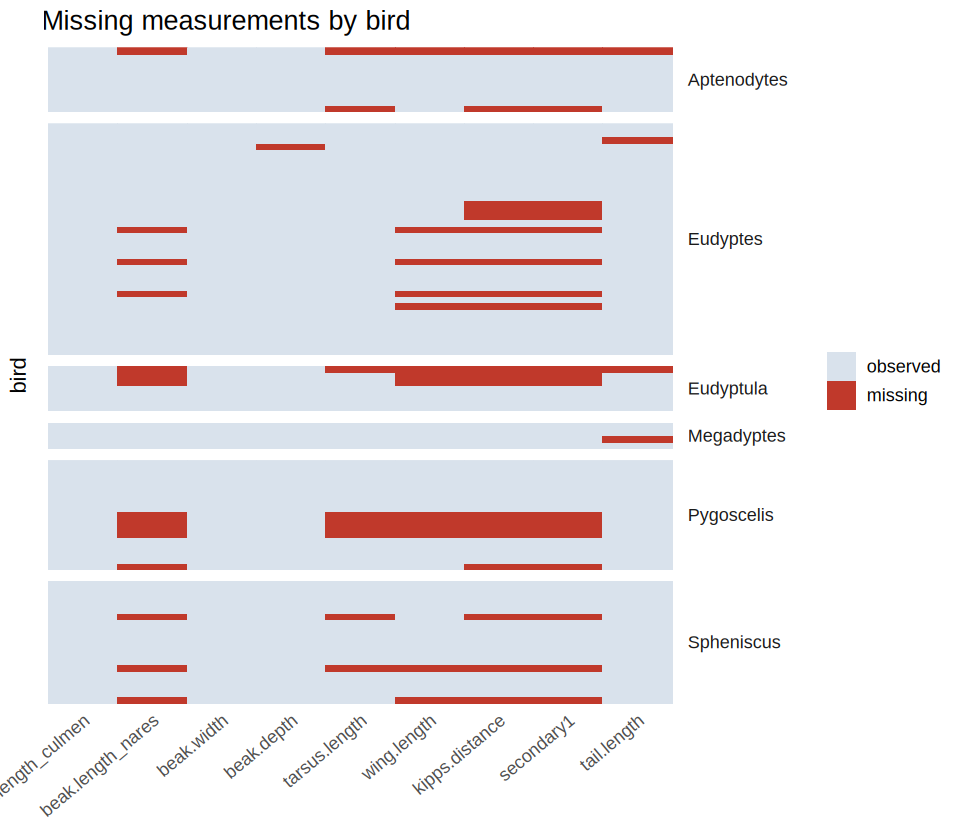

In [3]:
miss_long <- penguins |>
  mutate(bird = row_number()) |>
  select(bird, genus, species, all_of(traits)) |>
  pivot_longer(all_of(traits), names_to = "trait", values_to = "value") |>
  mutate(missing = is.na(value),
         trait = factor(trait, levels = traits))

p_miss <- ggplot(miss_long, aes(trait, factor(bird), fill = missing)) +
  geom_tile() +
  scale_fill_manual(values = c(`FALSE` = "#d9e2ec", `TRUE` = "#c0392b"),
                    labels = c("observed", "missing"), name = NULL) +
  facet_grid(genus ~ ., scales = "free_y", space = "free_y") +
  labs(x = NULL, y = "bird", title = "Missing measurements by bird") +
  theme(axis.text.y = element_blank(), panel.grid = element_blank(),
        axis.text.x = element_text(angle = 40, hjust = 1),
        strip.text.y = element_text(angle = 0, hjust = 0))
options(repr.plot.width = 8, repr.plot.height = 7)
p_miss
ggsave(file.path(fig_dir, "missingness.png"), p_miss, width = 8, height = 7, dpi = 150, bg = "white")

In [4]:
complete <- complete.cases(penguins[traits])
cat("Birds with all", length(traits), "traits:", sum(complete), "of", nrow(penguins), "\n")
cat("Observed measurements thrown away by complete-case analysis:",
    sum(!is.na(penguins[!complete, traits])), "\n")

# Which species lose birds (or disappear entirely) under complete-case analysis?
penguins |>
  mutate(complete = complete) |>
  group_by(genus, species) |>
  summarise(n_birds = n(), n_complete = sum(complete), .groups = "drop") |>
  filter(n_complete < n_birds) |>
  arrange(n_complete)

Birds with all 9 traits: 70 of 93 


Observed measurements thrown away by complete-case analysis: 124 


genus,species,n_birds,n_complete
<chr>,<chr>,<int>,<int>
Eudyptes,Eudyptes pachyrhynchus,4,1
Eudyptes,Eudyptes sclateri,4,2
Megadyptes,Megadyptes antipodes,4,3
Aptenodytes,Aptenodytes forsteri,5,4
Aptenodytes,Aptenodytes patagonicus,5,4
Eudyptes,Eudyptes chrysolophus,5,4
Eudyptes,Eudyptes moseleyi,5,4
Eudyptula,Eudyptula minor,7,4
Pygoscelis,Pygoscelis adeliae,5,4


**What we see.** The gaps come in **blocks**: every bird missing Kipp's distance is
also missing secondary-feather length, and most of them are missing wing length too.
For those birds the whole set of wing measurements was never taken. The gaps are spread
over 14 of the 18 species, usually one bird per species.

Complete-case analysis keeps every species, but it drops 23 of 93 birds (25%), and
with them every measurement that *was* taken on those birds. Two crested-penguin
species fall to only one or two birds.

## 2. Three ordinations

All traits are log-transformed (so they are on a relative scale) and standardized
(mean 0, SD 1, computed from the observed values).

In [5]:
X_log <- penguins |>
  select(all_of(traits)) |>
  mutate(across(everything(), log)) |>
  as.matrix()

# standardize with observed means / SDs
mu  <- colMeans(X_log, na.rm = TRUE)
sdv <- apply(X_log, 2, sd, na.rm = TRUE)
Z   <- sweep(sweep(X_log, 2, mu), 2, sdv, "/")
round(colMeans(is.na(Z)) * 100, 1)

beak.length_culmen  beak.length_nares         beak.width         beak.depth 
               0.0               16.1                0.0                1.1 
     tarsus.length        wing.length     kipps.distance         secondary1 
               9.7               15.1               21.5               21.5 
       tail.length 
               4.3

### B. Regularized iterative PCA imputation

This is the algorithm behind `missMDA::imputePCA` (Josse & Husson 2012), written out
here in a few lines of base R:

1. Fill each missing cell with its column mean.
2. Fit a PCA with `ncp` components to the filled matrix.
3. Replace **only the missing cells** with their low-rank PCA reconstruction.
4. Repeat steps 2–3 until the filled-in values stop changing.

The *regularized* version shrinks the singular values a little, so that a small, noisy
dataset like this one does not overfit.

In [6]:
impute_pca <- function(Z, ncp = 2, maxit = 1000, tol = 1e-7, regularized = TRUE) {
  miss <- is.na(Z)
  X <- Z
  X[miss] <- matrix(colMeans(Z, na.rm = TRUE), nrow(Z), ncol(Z), byrow = TRUE)[miss]
  n <- nrow(X); p <- ncol(X)
  for (it in seq_len(maxit)) {
    m  <- colMeans(X)
    Xc <- sweep(X, 2, m)
    s  <- svd(Xc)
    d  <- s$d[1:ncp]
    if (regularized) {
      lambda <- s$d^2 / n                       # PCA eigenvalues
      sigma2 <- mean(lambda[(ncp + 1):p])       # noise variance estimate
      d <- d * pmax(lambda[1:ncp] - sigma2, 0) / lambda[1:ncp]
    }
    fit <- s$u[, 1:ncp, drop = FALSE] %*% diag(d, ncp) %*% t(s$v[, 1:ncp, drop = FALSE])
    fit <- sweep(fit, 2, m, "+")
    change <- sum((X[miss] - fit[miss])^2) / max(sum(X[miss]^2), 1e-12)
    X[miss] <- fit[miss]
    if (change < tol) break
  }
  attr(X, "iterations") <- it
  X
}

### Choosing the number of components (and checking that imputation works)

We use the 70 birds that have every trait. In each of 100 rounds we hide some values,
following the real pattern: we copy the missingness pattern of a randomly chosen
incomplete bird onto a randomly chosen complete bird, for 15 birds per round. We then
impute the hidden values and measure the error (RMSE, in standard-deviation units of
the log trait). The methods compared are:

* **column mean** (the naive fill)
* **iterative PCA** with 1–4 components
* **species mean** (a reference that *uses the species labels*; an unsupervised ordination cannot use these)

In [7]:
Zc       <- Z[complete, ]
species_c <- penguins$species[complete]
patterns <- is.na(Z[!complete, ])          # real missingness patterns

one_round <- function() {
  Zm <- Zc
  targets <- sample(nrow(Zc), 15)
  for (i in targets) Zm[i, patterns[sample(nrow(patterns), 1), ]] <- NA
  hid <- is.na(Zm)
  truth <- Zc[hid]
  rmse <- function(est) sqrt(mean((est[hid] - truth)^2))

  col_mean <- Zm
  col_mean[hid] <- matrix(colMeans(Zm, na.rm = TRUE), nrow(Zm), ncol(Zm), byrow = TRUE)[hid]

  sp_mean <- Zm
  for (j in seq_len(ncol(Zm))) {
    m <- ave(Zm[, j], species_c, FUN = function(v) mean(v, na.rm = TRUE))
    m[is.nan(m)] <- mean(Zm[, j], na.rm = TRUE)   # species with no observed value
    sp_mean[hid[, j], j] <- m[hid[, j]]
  }

  c(`column mean`        = rmse(col_mean),
    `iterative PCA, 1 PC` = rmse(impute_pca(Zm, 1)),
    `iterative PCA, 2 PCs` = rmse(impute_pca(Zm, 2)),
    `iterative PCA, 3 PCs` = rmse(impute_pca(Zm, 3)),
    `iterative PCA, 4 PCs` = rmse(impute_pca(Zm, 4)),
    `species mean (uses labels)` = rmse(sp_mean))
}

cv <- t(replicate(100, one_round()))
cv_summary <- tibble(method = colnames(cv),
                     mean_rmse = colMeans(cv),
                     se = apply(cv, 2, sd) / sqrt(nrow(cv))) |>
  mutate(across(where(is.numeric), ~ round(.x, 3)))
cv_summary

method,mean_rmse,se
<chr>,<dbl>,<dbl>
column mean,0.981,0.013
"iterative PCA, 1 PC",0.721,0.009
"iterative PCA, 2 PCs",0.652,0.009
"iterative PCA, 3 PCs",0.636,0.009
"iterative PCA, 4 PCs",0.629,0.009
species mean (uses labels),0.468,0.008


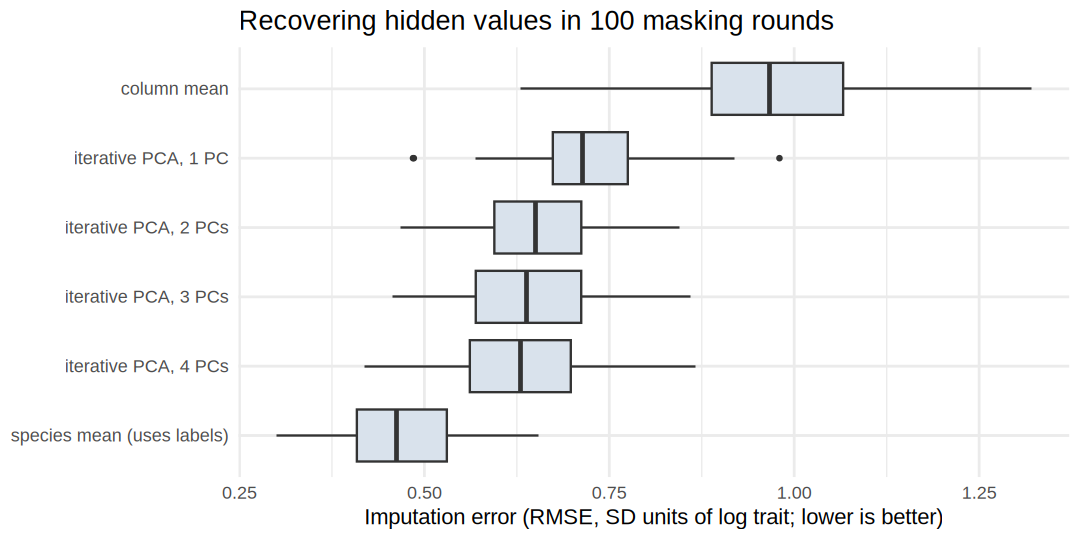

In [8]:
cv_long <- as_tibble(cv) |>
  pivot_longer(everything(), names_to = "method", values_to = "rmse") |>
  mutate(method = factor(method, levels = rev(colnames(cv))))

p_cv <- ggplot(cv_long, aes(rmse, method)) +
  geom_boxplot(fill = "#d9e2ec", outlier.size = 0.8) +
  labs(x = "Imputation error (RMSE, SD units of log trait; lower is better)", y = NULL,
       title = "Recovering hidden values in 100 masking rounds")
options(repr.plot.width = 9, repr.plot.height = 4.5)
p_cv
ggsave(file.path(fig_dir, "imputation_cv.png"), p_cv, width = 9, height = 4.5, dpi = 150, bg = "white")

In [9]:
best_ncp <- as.integer(sub(".*, (\\d) PC.*", "\\1",
  cv_summary$method[grepl("iterative", cv_summary$method)][
    which.min(cv_summary$mean_rmse[grepl("iterative", cv_summary$method)])]))
cat("Number of components chosen for imputation:", best_ncp, "\n")
Z_imp <- impute_pca(Z, ncp = best_ncp)
cat("Converged after", attr(Z_imp, "iterations"), "iterations\n")

Number of components chosen for imputation: 4 


Converged after 48 iterations


### Fit the three ordinations

In [10]:
# A. complete-case PCA (70 birds)
pca_cc  <- prcomp(Z[complete, ], center = TRUE, scale. = FALSE)

# B. PCA on the iteratively imputed matrix (93 birds)
pca_imp <- prcomp(Z_imp, center = TRUE, scale. = FALSE)

# C. Gower distance (uses only the traits both birds share) + classical MDS / PCoA
gower  <- daisy(as.data.frame(Z), metric = "gower")
pcoa   <- cmdscale(sqrt(gower), k = 2, eig = TRUE)

var_expl <- function(sdev) round(100 * sdev^2 / sum(sdev^2), 1)
tibble(
  method = c("A. complete-case PCA", "B. imputed PCA", "C. Gower PCoA"),
  n_birds = c(nrow(pca_cc$x), nrow(pca_imp$x), nrow(pcoa$points)),
  axis1_pct = c(var_expl(pca_cc$sdev)[1], var_expl(pca_imp$sdev)[1],
                round(100 * pcoa$eig[1] / sum(pmax(pcoa$eig, 0)), 1)),
  axis2_pct = c(var_expl(pca_cc$sdev)[2], var_expl(pca_imp$sdev)[2],
                round(100 * pcoa$eig[2] / sum(pmax(pcoa$eig, 0)), 1))
)

method,n_birds,axis1_pct,axis2_pct
<chr>,<int>,<dbl>,<dbl>
A. complete-case PCA,70,52.7,22.6
B. imputed PCA,93,54.1,21.2
C. Gower PCoA,93,24.3,16.4


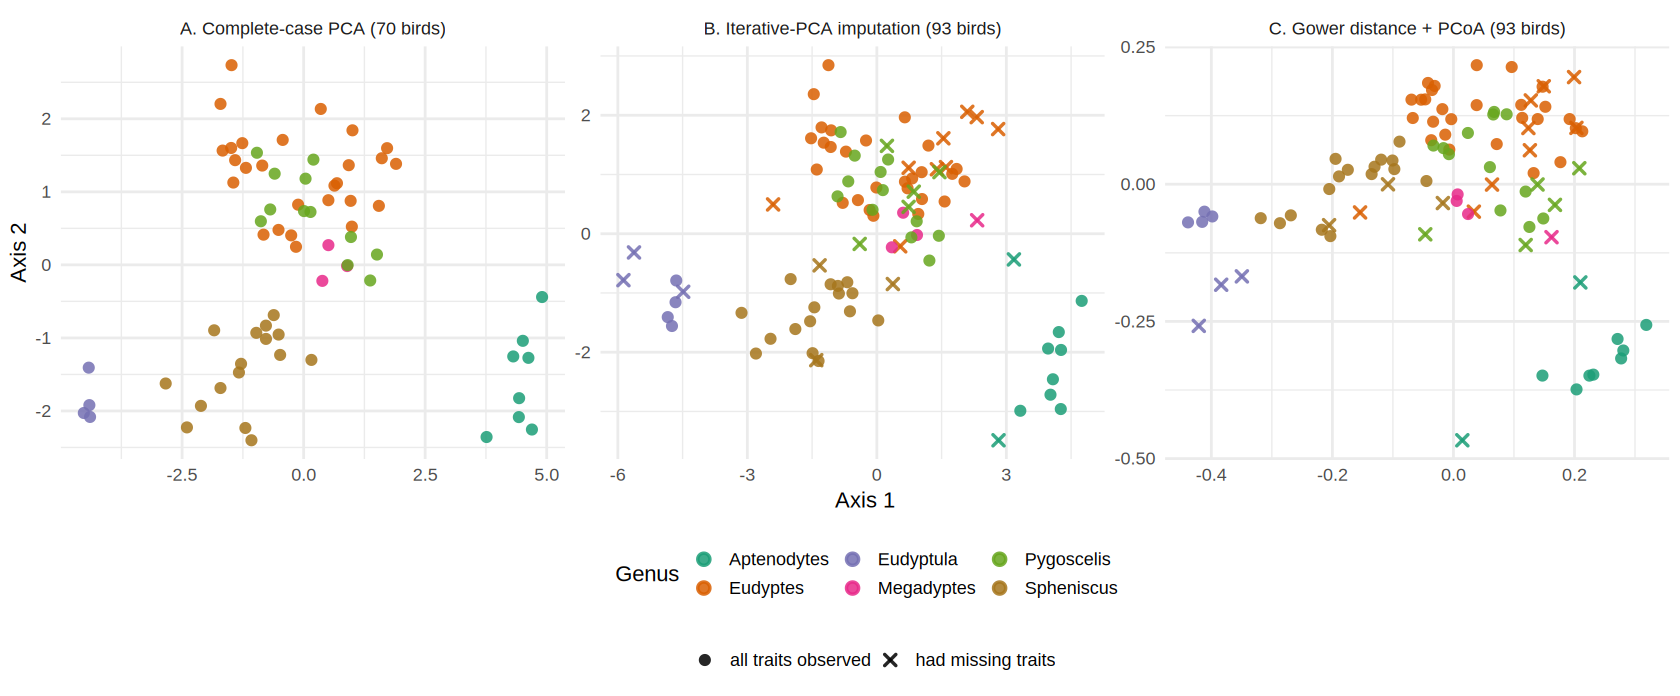

In [11]:
# Align signs so the three maps point the same way (PC signs are arbitrary):
# axis 1 increases with wing length, axis 2 increases with beak depth.
align <- function(scores, ref) {
  for (k in 1:2) if (cor(scores[, k], ref[, k], use = "complete.obs") < 0) scores[, k] <- -scores[, k]
  scores
}
ref <- cbind(Z_imp[, "wing.length"], Z_imp[, "beak.depth"])

scores <- bind_rows(
  tibble(method = "A. Complete-case PCA (70 birds)",
         bird = which(complete),
         as_tibble(align(pca_cc$x[, 1:2], ref[complete, ]), .name_repair = ~ c("ax1", "ax2"))),
  tibble(method = "B. Iterative-PCA imputation (93 birds)",
         bird = seq_len(nrow(Z)),
         as_tibble(align(pca_imp$x[, 1:2], ref), .name_repair = ~ c("ax1", "ax2"))),
  tibble(method = "C. Gower distance + PCoA (93 birds)",
         bird = seq_len(nrow(Z)),
         as_tibble(align(pcoa$points, ref), .name_repair = ~ c("ax1", "ax2")))
) |>
  mutate(genus = penguins$genus[bird],
         had_missing = !complete[bird])

p_ord <- ggplot(scores, aes(ax1, ax2, colour = genus)) +
  geom_point(aes(shape = had_missing), size = 2.4, stroke = 1.1, alpha = 0.85) +
  scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 4),
                     labels = c("all traits observed", "had missing traits"), name = NULL) +
  scale_colour_manual(values = genus_cols) +
  facet_wrap(~ method, scales = "free") +
  labs(x = "Axis 1", y = "Axis 2", colour = "Genus") +
  theme(legend.position = "bottom", legend.box = "vertical")
options(repr.plot.width = 14, repr.plot.height = 5.8)
p_ord
ggsave(file.path(fig_dir, "ordinations.png"), p_ord, width = 14, height = 5.8, dpi = 150, bg = "white")

### Do the maps agree?

We compare the methods on the 70 birds that appear in all three maps using a
**Procrustes correlation**: rotate, reflect and scale one configuration to best match
the other, then report how well they match (1 means identical).

In [12]:
procrustes_r <- function(A, B) {
  A <- scale(A, scale = FALSE); B <- scale(B, scale = FALSE)
  A <- A / sqrt(sum(A^2));      B <- B / sqrt(sum(B^2))
  sum(svd(t(A) %*% B)$d)
}
cc_scores  <- pca_cc$x[, 1:2]
imp_scores <- pca_imp$x[complete, 1:2]
gow_scores <- pcoa$points[complete, ]

tibble(
  comparison = c("A vs B (complete-case vs imputed PCA)",
                 "A vs C (complete-case PCA vs Gower PCoA)",
                 "B vs C (imputed PCA vs Gower PCoA)"),
  procrustes_r = round(c(procrustes_r(cc_scores, imp_scores),
                         procrustes_r(cc_scores, gow_scores),
                         procrustes_r(imp_scores, gow_scores)), 3)
)

comparison,procrustes_r
<chr>,<dbl>
A vs B (complete-case vs imputed PCA),0.999
A vs C (complete-case PCA vs Gower PCoA),0.962
B vs C (imputed PCA vs Gower PCoA),0.954


## 3. What do the axes mean?

The loadings of the imputed PCA show which measurements drive each axis.

trait,PC1,PC2
<chr>,<dbl>,<dbl>
beak.length_culmen,0.32,-0.39
beak.length_nares,0.39,-0.17
beak.width,0.28,0.48
beak.depth,0.15,0.31
tarsus.length,0.32,-0.37
wing.length,0.44,-0.08
kipps.distance,0.30,0.38
secondary1,0.44,-0.15
tail.length,0.25,0.43


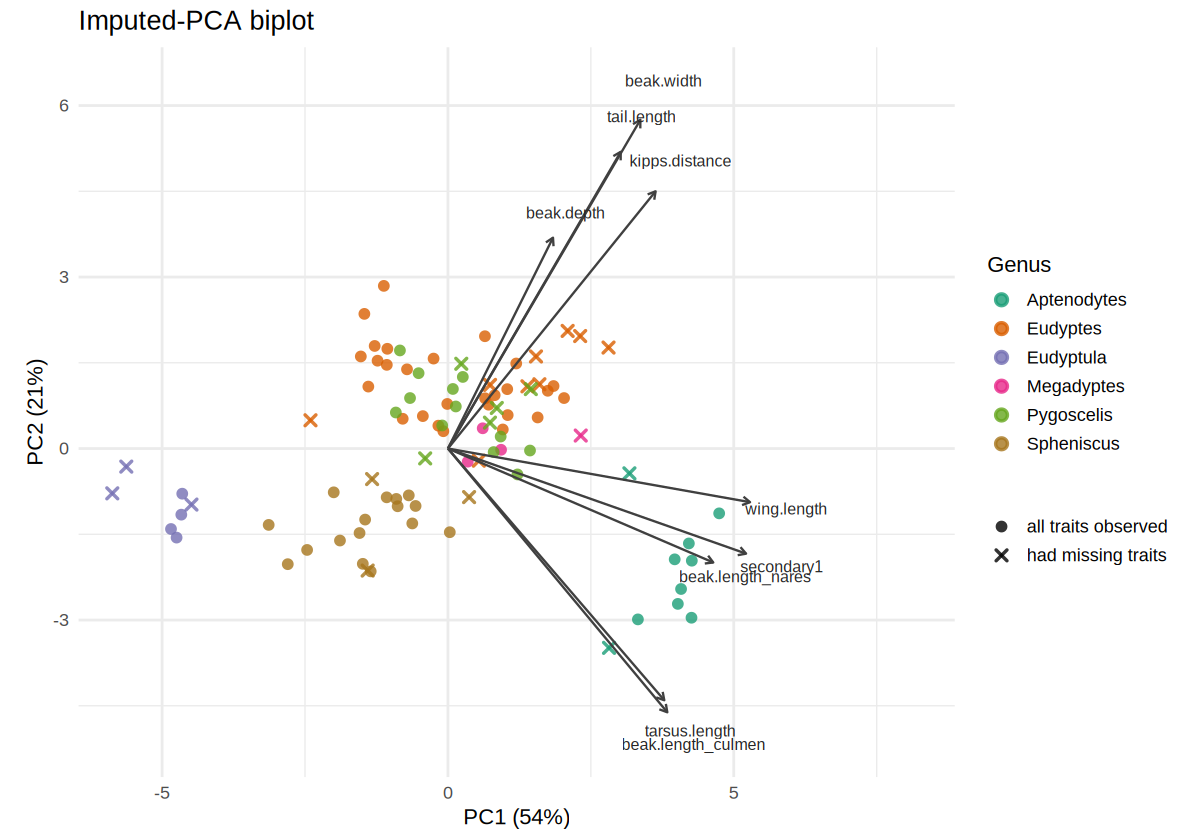

In [13]:
load_df <- as_tibble(pca_imp$rotation[, 1:2], rownames = "trait")
# use the same sign convention as the map
for (k in 1:2) if (cor(pca_imp$x[, k], ref[, k]) < 0) load_df[[k + 1]] <- -load_df[[k + 1]]

sc <- as_tibble(align(pca_imp$x[, 1:2], ref), .name_repair = ~ c("PC1", "PC2")) |>
  mutate(genus = penguins$genus, had_missing = !complete)
arrow_scale <- 0.9 * max(abs(sc$PC1)) / max(abs(load_df$PC1))

p_biplot <- ggplot(sc, aes(PC1, PC2)) +
  geom_point(aes(colour = genus, shape = had_missing), size = 2.3, stroke = 1.1, alpha = 0.8) +
  geom_segment(data = load_df, aes(x = 0, y = 0, xend = PC1 * arrow_scale, yend = PC2 * arrow_scale),
               arrow = arrow(length = unit(0.18, "cm")), colour = "grey25") +
  geom_text(data = load_df, aes(x = PC1 * arrow_scale * 1.12, y = PC2 * arrow_scale * 1.12, label = trait),
            size = 3.2, colour = "grey15") +
  scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 4),
                     labels = c("all traits observed", "had missing traits"), name = NULL) +
  scale_colour_manual(values = genus_cols) +
  labs(x = sprintf("PC1 (%.0f%%)", var_expl(pca_imp$sdev)[1]),
       y = sprintf("PC2 (%.0f%%)", var_expl(pca_imp$sdev)[2]),
       colour = "Genus", title = "Imputed-PCA biplot") +
  scale_x_continuous(expand = expansion(mult = c(0.05, 0.25))) +
  coord_equal(clip = "off")
options(repr.plot.width = 10, repr.plot.height = 7)
p_biplot
ggsave(file.path(fig_dir, "biplot.png"), p_biplot, width = 10, height = 7, dpi = 150, bg = "white")

load_df |> mutate(across(where(is.numeric), ~ round(.x, 2)))

## Conclusions

* **Complete-case PCA throws away a quarter of the birds**, along with the
  measurements that *were* taken on them, and leaves some species with only 1–2 birds.
* **Regularized iterative PCA imputation** keeps all 93 birds. In the masking
  experiment it cut the error of the filled-in values by about a third compared with
  column-mean filling (RMSE ≈ 0.63 vs 0.98 SD), using only the correlations among
  traits. Adding components helps, but the gains are small after 2–3.
  Species-mean filling is more accurate still (≈ 0.47), but it needs the species
  labels, which an exploratory ordination should not rely on.
* On the 70 birds that appear in every map, the imputed PCA is almost identical to the
  complete-case PCA (Procrustes r ≈ 0.999). Adding the 23 imputed birds **did not
  distort the map**, and those birds (× symbols) fall inside their own genus's cluster.
* **Gower distance + PCoA** needs no imputation at all and gives a very similar map
  (Procrustes r ≈ 0.95–0.96), which makes it a useful robustness check.
* All three maps tell the same story:
  * **Axis 1 (~54%) is overall size.** It runs from *Eudyptula* (little penguins) to *Aptenodytes* (king and emperor penguins), and every trait loads positively.
  * **Axis 2 (~21%) is shape.** It runs from wide bills, long tails and long Kipp's distance (*Eudyptes*, the crested penguins, and *Pygoscelis*, the brush-tailed penguins) to long, slender bills, long tarsi and short tails (*Spheniscus*, the banded penguins, and *Aptenodytes*).

**Recommendation:** use iterative PCA imputation (`missMDA::imputePCA` in practice)
for the main map, and mark the birds that had imputed values (× symbols) so readers
can see which points are less certain. Gower PCoA is a useful robustness check.

**Caveats.** Imputation assumes values are *missing at random* given the observed
traits. If a measurement was skipped *because* of something about the bird, the
filled-in values could be biased. Most species also have only 4–5 birds, so
species-level positions on the map are uncertain.